# ☀️ Space Weather & Solar Physics: NOAA GOES Solar Flare Spikes
## Extreme Coronal Mass Ejections, Multi-Magnitude X-Ray Radiation Explosions & Geomagnetic Shocks

### 1. Incident Background & Multi-Spike Radiation Dynamics
In solar astrophysics and space weather forecasting, solar flares are explosive releases of magnetic energy in the Sun's corona. When magnetic reconnection occurs in active sunspot regions, the Sun emits intense bursts of electromagnetic radiation across the X-ray and EUV spectrum.

The **NOAA Space Weather Prediction Center (SWPC)** monitors real-time solar X-ray flux using primary **GOES (Geostationary Operational Environmental Satellite)** instruments at 1-minute cadence in two wavelength bands:
* **Shortwave (`0.05 - 0.4 nm`)**
* **Longwave (`0.1 - 0.8 nm`)**

### 2. Multi-Magnitude Logarithmic Shock Classification
Solar flares are classified on a logarithmic scale based on peak longwave X-ray flux ($W/m^2$):
* **A-Class ($< 10^{-7} \text{W/m}^2$):** Background quiet solar state.
* **B-Class ($10^{-7} \text{ to } 10^{-6} \text{W/m}^2$):** Low background activity.
* **C-Class ($10^{-6} \text{ to } 10^{-5} \text{W/m}^2$):** Small flares with minor terrestrial impact.
* **M-Class ($10^{-5} \text{ to } 10^{-4} \text{W/m}^2$):** Medium-strength flares causing brief high-frequency radio blackouts at Earth's polar caps.
* **X-Class ($\ge 10^{-4} \text{W/m}^2$):** Major coronal explosions that trigger planet-wide radio blackouts, satellite telemetry interference, and extreme geomagnetic storms (e.g. the historic May 2024 G5 solar storm).

When a flare erupts, radiation **explodes by 2 to 4 orders of magnitude within 5 to 15 minutes**, followed by hours of gradual thermal plasma cooling.

### 3. Data Source
* NOAA Space Weather Prediction Center (SWPC) REST API (`services.swpc.noaa.gov/json/goes/primary/xrays-7-day.json`).
* 100% public, real-time satellite telemetry, zero authentication.


### 📚 Academic Citations & Benchmark Lineage
* **Solar Self-Organized Criticality:** Aschwanden, M. J. (2020). *"Order out of Randomness in the Solar Corona: Self-Organized Criticality and Extreme Solar Flares."* *The Astrophysical Journal*, 896(2), 162.
* **Satellite Telemetry Source:** NOAA Space Weather Prediction Center (SWPC) GOES Primary Satellite Series.
* **BibTeX Citation:**
```bibtex
@article{aschwanden2020order,
  title={Order out of Randomness in the Solar Corona: Self-Organized Criticality and Extreme Solar Flares},
  author={Aschwanden, Markus J},
  journal={The Astrophysical Journal},
  volume={896},
  number={2},
  pages={162},
  year={2020}
}
```

In [1]:
import os
import requests
import datetime
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.signal import find_peaks

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
os.makedirs('data', exist_ok=True)
print("Environment initialized successfully!")

Environment initialized successfully!


### 4. Data Ingestion & Local Caching

In [2]:
def fetch_noaa_solar_xrays(cache_dir='data'):
    cache_path = os.path.join(cache_dir, 'noaa_solar_xrays_raw.csv')
    
    if os.path.exists(cache_path):
        print(f"Loading cached NOAA solar X-ray telemetry from: {cache_path}")
        df = pd.read_csv(cache_path)
        df['time_tag'] = pd.to_datetime(df['time_tag'])
        return df
    
    print("Fetching high-frequency solar X-ray telemetry from NOAA SWPC...")
    url = 'https://services.swpc.noaa.gov/json/goes/primary/xrays-7-day.json'
    response = requests.get(url, timeout=30)
    response.raise_for_status()
    data = response.json()
    
    df_raw = pd.DataFrame(data)
    df_raw.to_csv(cache_path, index=False)
    print(f"Downloaded and cached {len(df_raw):,} raw X-ray readings.")
    df_raw['time_tag'] = pd.to_datetime(df_raw['time_tag'])
    return df_raw

df_xray_raw = fetch_noaa_solar_xrays()
df_xray_raw.head()

Fetching high-frequency solar X-ray telemetry from NOAA SWPC...


Downloaded and cached 20,138 raw X-ray readings.


,time_tag,satellite,flux,observed_flux,electron_correction,electron_contaminaton,energy
0,2026-10-21 12:21:00+00:00,18,1.000000e-09,2.192674e-09,2.901902e-09,True,0.05-0.4nm
1,2026-10-21 12:21:00+00:00,18,5.877546e-07,6.001155e-07,1.236088e-08,False,0.1-0.8nm
2,2026-10-21 12:22:00+00:00,18,1.000000e-09,2.766533e-09,2.997202e-09,True,0.05-0.4nm
3,2026-10-21 12:22:00+00:00,18,5.815403e-07,5.943299e-07,1.278960e-08,False,0.1-0.8nm
4,2026-10-21 12:23:00+00:00,18,1.000000e-09,3.285123e-09,2.947614e-09,True,0.05-0.4nm


### 5. Solar Flare Feature Engineering & Log-Scale Shock Segmentation

In [3]:
# Filter to standard longwave band (0.1 - 0.8 nm) used for official NOAA flare classification
df_solar = df_xray_raw[df_xray_raw['energy'] == '0.1-0.8nm'].copy()
df_solar['flux'] = pd.to_numeric(df_solar['flux'], errors='coerce')
df_solar = df_solar.dropna(subset=['flux']).sort_values('time_tag').reset_index(drop=True)

# 1. Log10 Flux (orders of magnitude)
df_solar['log10_flux'] = np.log10(df_solar['flux'])

# 2. Flare Class Categorization
# A: < 1e-7, B: 1e-7 to 1e-6, C: 1e-6 to 1e-5, M: 1e-5 to 1e-4, X: >= 1e-4
def classify_flare(flux_val):
    if flux_val >= 1e-4:
        return f"X{flux_val/1e-4:.1f}"
    elif flux_val >= 1e-5:
        return f"M{flux_val/1e-5:.1f}"
    elif flux_val >= 1e-6:
        return f"C{flux_val/1e-6:.1f}"
    elif flux_val >= 1e-7:
        return f"B{flux_val/1e-7:.1f}"
    else:
        return "A"

df_solar['flare_class'] = df_solar['flux'].apply(classify_flare)

# 3. Flare Velocity (First Difference of log-flux / 1-min)
df_solar['flux_velocity_per_min'] = df_solar['flux'].diff()
df_solar['log_velocity_per_min'] = df_solar['log10_flux'].diff()

# 4. Trailing 6-hour baseline flux median
df_solar['baseline_6h_median'] = df_solar['flux'].rolling(360, min_periods=30).median()
df_solar['surge_multiplier'] = df_solar['flux'] / df_solar['baseline_6h_median']

# 5. Automated Peak Detection of Solar Flare Spikes
# Detect prominent peaks on log-scale
peaks, _ = find_peaks(df_solar['log10_flux'].values, distance=45, prominence=0.35)
df_solar['is_flare_peak'] = 0
df_solar.loc[peaks, 'is_flare_peak'] = 1

print(f"Total 1-Minute Telemetry Records:      {len(df_solar):,}")
print(f"Quiet Baseline Flux (Median):           {df_solar['flux'].median():.2e} W/m^2")
print(f"Maximum Solar Flare Peak:               {df_solar['flux'].max():.2e} W/m^2 ({classify_flare(df_solar['flux'].max())})")
print(f"Detected Prominent Flare Peaks:         {len(peaks)} spikes")
print(f"Peak Surge Multiplier vs Baseline:      +{df_solar['surge_multiplier'].max():.1f}x")
df_solar.head()

Total 1-Minute Telemetry Records:      10,069
Quiet Baseline Flux (Median):           4.41e-07 W/m^2
Maximum Solar Flare Peak:               3.55e-06 W/m^2 (C3.5)
Detected Prominent Flare Peaks:         27 spikes
Peak Surge Multiplier vs Baseline:      +7.6x


,time_tag,satellite,flux,observed_flux,electron_correction,electron_contaminaton,energy,log10_flux,flare_class,flux_velocity_per_min,log_velocity_per_min,baseline_6h_median,surge_multiplier,is_flare_peak
0,2026-10-21 12:21:00+00:00,18,5.877546e-07,6.001155e-07,1.236088e-08,False,0.1-0.8nm,-6.230804,B5.9,NaN,NaN,NaN,NaN,0
1,2026-10-21 12:22:00+00:00,18,5.815403e-07,5.943299e-07,1.278960e-08,False,0.1-0.8nm,-6.235420,B5.8,-6.214293e-09,-0.004616,NaN,NaN,0
2,2026-10-21 12:23:00+00:00,18,5.785443e-07,5.905812e-07,1.203691e-08,False,0.1-0.8nm,-6.237663,B5.8,-2.996046e-09,-0.002243,NaN,NaN,0
3,2026-10-21 12:24:00+00:00,18,5.824449e-07,5.943783e-07,1.193334e-08,False,0.1-0.8nm,-6.234745,B5.8,3.900595e-09,0.002918,NaN,NaN,0
4,2026-10-21 12:25:00+00:00,18,5.872097e-07,5.991582e-07,1.194847e-08,False,0.1-0.8nm,-6.231207,B5.9,4.764843e-09,0.003538,NaN,NaN,0


### 6. Timeline Visualizations of Satellite Solar Flare Spikes

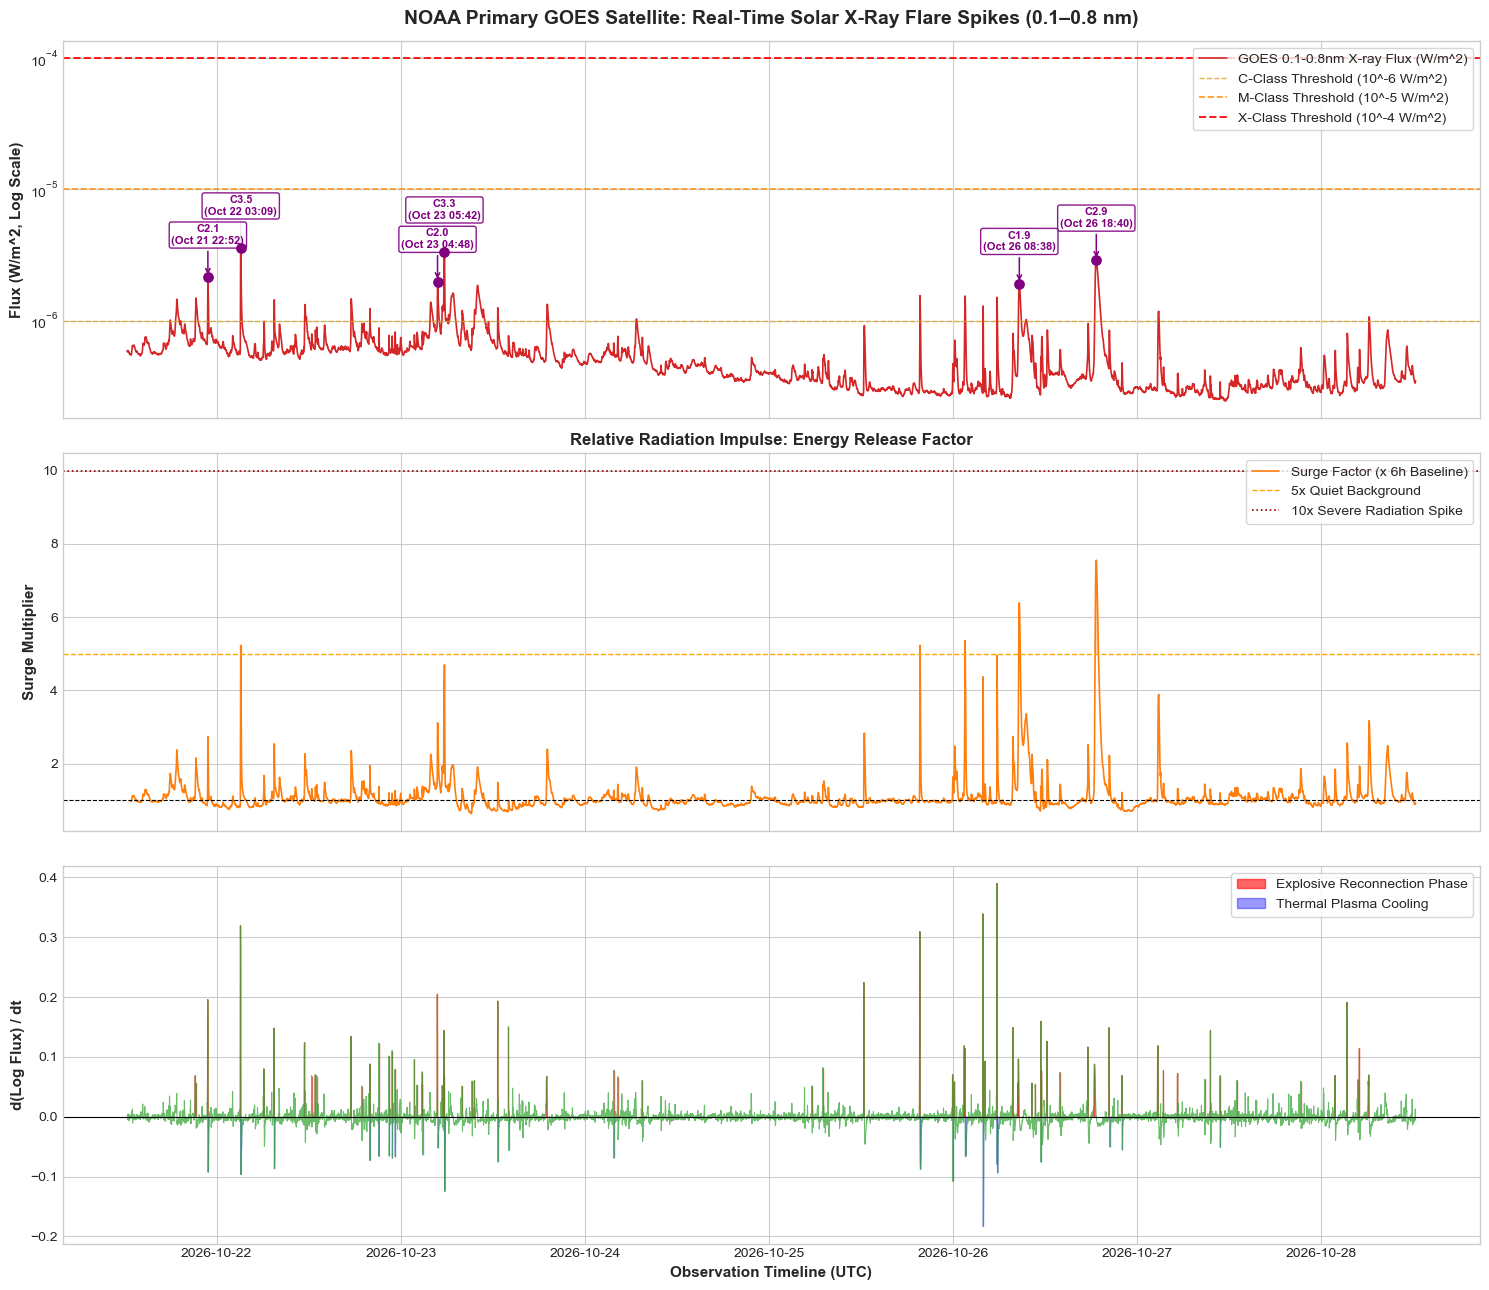

In [4]:
fig, axes = plt.subplots(3, 1, figsize=(15, 13), sharex=True)

# 1. Log-Scale Solar X-Ray Flux with NOAA Flare Class Bands
ax1 = axes[0]
ax1.plot(df_solar['time_tag'], df_solar['flux'], color='#d62728', lw=1.2, label='GOES 0.1-0.8nm X-ray Flux (W/m^2)')
ax1.set_yscale('log')

# Class boundary horizontal lines
ax1.axhline(1e-6, color='goldenrod', ls='--', lw=1.0, alpha=0.8, label='C-Class Threshold (10^-6 W/m^2)')
ax1.axhline(1e-5, color='darkorange', ls='--', lw=1.2, alpha=0.9, label='M-Class Threshold (10^-5 W/m^2)')
ax1.axhline(1e-4, color='red', ls='--', lw=1.4, alpha=0.9, label='X-Class Threshold (10^-4 W/m^2)')

# Annotate prominent detected flare peaks
top_peaks = df_solar[df_solar['is_flare_peak'] == 1].sort_values('flux', ascending=False).head(6)
for _, row in top_peaks.iterrows():
    ts = row['time_tag']
    val = row['flux']
    f_class = row['flare_class']
    ax1.scatter(ts, val, color='purple', s=45, zorder=5)
    ax1.annotate(f"{f_class}\n({ts.strftime('%b %d %H:%M')})", 
                 xy=(ts, val), xytext=(ts, val * 1.8),
                 arrowprops=dict(arrowstyle="->", color='purple', lw=1.1),
                 fontsize=8.0, fontweight='bold', color='purple', ha='center',
                 bbox=dict(boxstyle='round,pad=0.2', facecolor='white', alpha=0.9, edgecolor='purple'))

ax1.set_title("NOAA Primary GOES Satellite: Real-Time Solar X-Ray Flare Spikes (0.1–0.8 nm)", 
              fontsize=14, fontweight='bold', pad=12)
ax1.set_ylabel("Flux (W/m^2, Log Scale)", fontsize=11, fontweight='bold')
ax1.legend(loc='upper right', frameon=True)

# 2. Surge Multiplier Relative to Quiet Background
ax2 = axes[1]
ax2.plot(df_solar['time_tag'], df_solar['surge_multiplier'], color='#ff7f0e', lw=1.2, label='Surge Factor (x 6h Baseline)')
ax2.axhline(1.0, color='black', lw=0.8, ls='--')
ax2.axhline(5.0, color='orange', ls='--', lw=1.0, label='5x Quiet Background')
ax2.axhline(10.0, color='darkred', ls=':', lw=1.2, label='10x Severe Radiation Spike')
ax2.fill_between(df_solar['time_tag'], 5.0, df_solar['surge_multiplier'], 
                 where=(df_solar['surge_multiplier'] >= 5.0), color='#ff7f0e', alpha=0.3)
ax2.set_ylabel("Surge Multiplier", fontsize=11, fontweight='bold')
ax2.set_title("Relative Radiation Impulse: Energy Release Factor", fontsize=12, fontweight='bold')
ax2.legend(loc='upper right', frameon=True)

# 3. Log-Flux Velocity (Instantaneous Explosion Rate / min)
ax3 = axes[2]
ax3.plot(df_solar['time_tag'], df_solar['log_velocity_per_min'], color='#2ca02c', lw=0.8, alpha=0.7)
ax3.fill_between(df_solar['time_tag'], 0, df_solar['log_velocity_per_min'], 
                 where=(df_solar['log_velocity_per_min'] > 0.05), color='red', alpha=0.6, label='Explosive Reconnection Phase')
ax3.fill_between(df_solar['time_tag'], 0, df_solar['log_velocity_per_min'], 
                 where=(df_solar['log_velocity_per_min'] < -0.05), color='blue', alpha=0.4, label='Thermal Plasma Cooling')
ax3.axhline(0, color='black', lw=0.8)
ax3.set_ylabel("d(Log Flux) / dt", fontsize=11, fontweight='bold')
ax3.set_xlabel("Observation Timeline (UTC)", fontsize=11, fontweight='bold')
ax3.legend(loc='upper right', frameon=True)

plt.tight_layout()
plt.savefig('data/noaa_solar_flares_timeline.png', dpi=300)
plt.show()

### 7. Solar Flare Spike Ranking Table & Processed Export

In [5]:
# Summary table of detected flare peaks
flares_df = df_solar[df_solar['is_flare_peak'] == 1].sort_values('flux', ascending=False).head(12)
flare_table = flares_df[['time_tag', 'flux', 'flare_class', 'surge_multiplier', 'log_velocity_per_min']].copy()
flare_table['time_tag'] = flare_table['time_tag'].dt.strftime('%Y-%m-%d %H:%M')
print("=== Top Detected NOAA Solar Flare Radiation Spikes ===")
print(flare_table.to_string(index=False))

# Export clean processed dataset
out_path = 'data/noaa_solar_flares_processed.csv'
df_solar.to_csv(out_path, index=False)
print(f"\nProcessed solar flare dataset successfully saved to: {out_path}")

=== Top Detected NOAA Solar Flare Radiation Spikes ===
        time_tag     flux flare_class  surge_multiplier  log_velocity_per_min
2026-10-22 03:09 0.000004        C3.5          5.228174              0.067495
2026-10-23 05:42 0.000003        C3.3          4.695607              0.069274
2026-10-26 18:40 0.000003        C2.9          7.553351              0.000827
2026-10-21 22:52 0.000002        C2.1          2.739040              0.134469
2026-10-23 04:48 0.000002        C2.0          3.113434              0.059438
2026-10-26 08:38 0.000002        C1.9          6.388683              0.002266
2026-10-23 10:01 0.000002        C1.9          1.910346              0.004956
2026-10-25 19:42 0.000002        C1.5          5.226885              0.002099
2026-10-26 01:34 0.000002        C1.5          5.360745              0.030226
2026-10-26 05:44 0.000002        C1.5          4.961054              0.158041
2026-10-21 21:19 0.000001        C1.5          2.155243              0.014568
2026-10-2